# L2 vs distance to the nearest fish and the nearest electrode, correct vs wrong (3 fish)

Fish 0 (C) is the emitter. For each EOD: L2 between the max-normalized predicted (fish 0) and recorded 10-pair patterns,
- **mine**: BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip, sign fixed (column `distance fish 0 | ...` of `eod_assignments.csv`);
- **Denis**: his pipeline (latest run, SLEAP midline), `‖normalized_predicted_PTP_C − normalized_recorded_PTP‖`.

Each EOD is split by whether that pipeline assigned it to fish 0 (correct) or not (wrong).
- distance to the nearest fish: `gap_cm`, fish 0 mask to the nearest other mask, edge to edge;
- distance to the nearest electrode: fish 0 mask (any pixel) to the nearest of the 20 electrode poles.

Lines: median per bin, band: interquartile range, bins with fewer than `MIN_N` EODs are not drawn.

In [1]:
import pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mask_metrics as mm                          # sets the Agg backend
%matplotlib inline

RES = 'results/eod_ground_truth_3fish/conductivities'
OUT = f'{RES}/l2_vs_distance_correct_vs_wrong'
MINE = 'BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip'
DENIS_PKL = 'results/eod_assignment_3_fish_silent/electrodes_3-fish/Assigned_Data_3fish_2024-10-15T14_12_25.pkl'
TRACK = 'data/3_fish_silent/elephantnose_20241015T141225_tracking_final.pkl'
ELECTRODES = 'data/electrodes/electrodes_signed_px_coord_3-fish.csv'
BETTER = 'results/eod_ground_truth_3fish/good_frames_better_list.csv'
EMITTER, PX_TO_CM, MIN_N = 0, 60 / 912, 10
import os; os.makedirs(OUT, exist_ok=True)

A = pd.read_csv(f'{RES}/eod_assignments.csv', index_col='row')
den = pd.read_pickle(DENIS_PKL)
assert (den.Frame.to_numpy() == A.Frame.to_numpy()).all()
better = A.Frame.isin(pd.read_csv(BETTER).frame).to_numpy()
print(f'{len(A):,} EODs, {better.sum():,} on the better list')

19,796 EODs, 6,751 on the better list


## 1. Per-EOD L2, correctness and distances

In [2]:
el = pd.read_csv(ELECTRODES)
poles = np.vstack([el[['x1', 'y1']].to_numpy(), el[['x2', 'y2']].to_numpy()])           # (20, 2) px, (x, y)
with open(TRACK, 'rb') as f: frames = pickle.load(f)['frames']

def electrode_distance(k):
    '''Fish 0 mask (any pixel) to the nearest electrode pole (cm); NaN without a single mask.'''
    hits = [(p, b) for l, p, b in zip(frames[k]['labels'], frames[k]['masks'], frames[k]['boxes']) if l == EMITTER]
    if len(hits) != 1: return np.nan
    (packed, (y0, y1, x0, x1)), = hits
    r, c = np.nonzero(mm.unpack_crop(packed, (y0, y1, x0, x1)))
    if len(r) == 0: return np.nan
    xy = np.column_stack([c + x0, r + y0])
    return np.sqrt(((xy[:, None] - poles[None]) ** 2).sum(-1).min()) * PX_TO_CM

frame_dist = {k: electrode_distance(k) for k in np.unique(A.Frame)}
D = pd.DataFrame({
    'Frame': A.Frame, 'better list': better,
    'fish distance (cm)': A.gap_cm, 'electrode distance (cm)': A.Frame.map(frame_dist),
    'L2 mine': A[f'distance fish {EMITTER} | {MINE}'], 'correct mine': A[f'fish | {MINE}'] == EMITTER,
    'L2 Denis': np.linalg.norm(np.stack(den.normalized_predicted_PTP_C) - np.stack(den.normalized_recorded_PTP), axis=1),
    'correct Denis': (A["fish | Denis' pipeline (latest run)"] == EMITTER).to_numpy()})
D.to_csv(f'{OUT}/l2_distance_per_eod.csv')
D.describe().round(2)

/private/tmp/claude-501/-Volumes-Lenca-SSD-github-EODAssignment/241fe84a-549d-4982-9076-fc323122aa8e/scratchpad/venv313/lib/python3.13/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Frame,fish distance (cm),electrode distance (cm),L2 mine,L2 Denis
count,19796.00,19768.00,19768.00,19796.00,19796.00
mean,14855.21,12.38,10.29,inf,0.87
std,8778.73,10.81,7.17,NaN,0.64
min,1.00,0.00,0.00,0.01,0.01
25%,7434.75,3.69,1.77,0.35,0.38
50%,14701.50,10.52,13.63,0.58,0.66
75%,21493.25,17.48,16.27,1.04,1.21
max,38580.00,53.46,24.14,inf,3.28


## 2. L2 vs distance, correct vs wrong

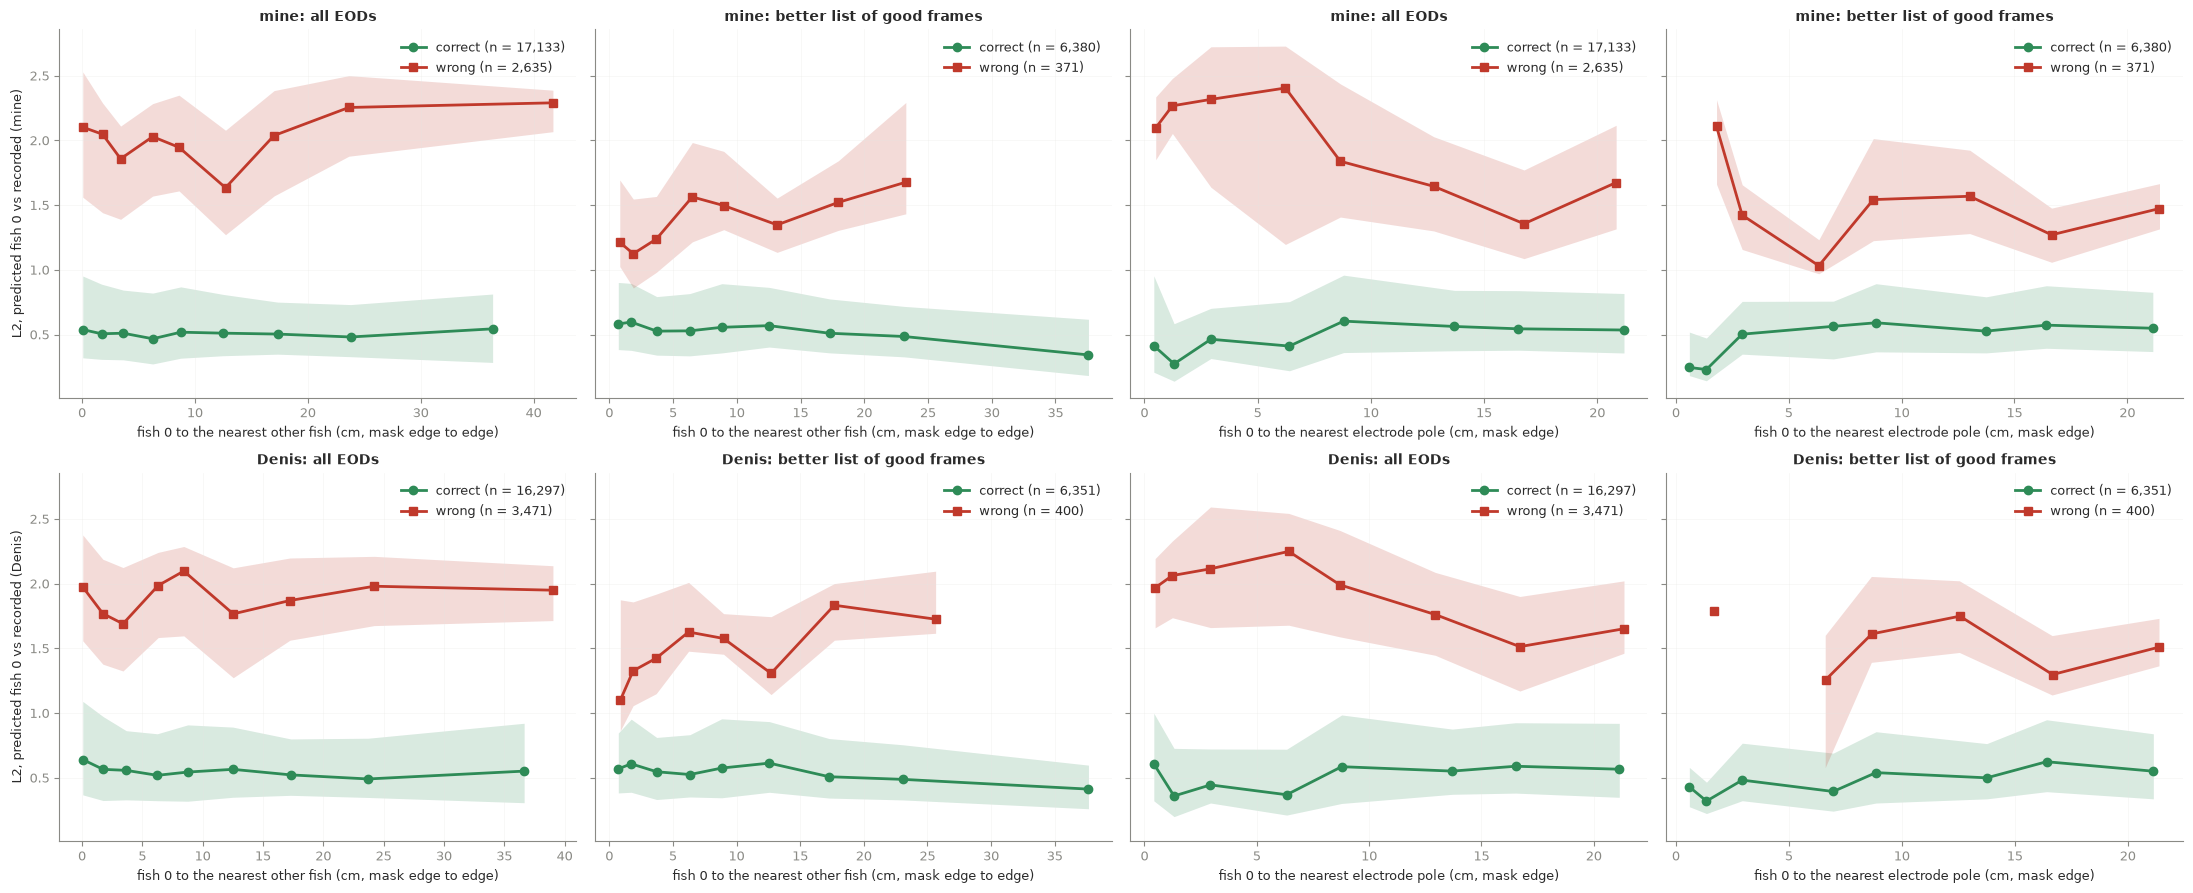

In [3]:
BINS = {'fish distance (cm)': [0, 1, 2.5, 5, 7.5, 10, 15, 20, 30, 55],
        'electrode distance (cm)': [0, 1, 2.5, 5, 7.5, 10, 15, 20, 30]}
XLABEL = {'fish distance (cm)': 'fish 0 to the nearest other fish (cm, mask edge to edge)',
          'electrode distance (cm)': 'fish 0 to the nearest electrode pole (cm, mask edge)'}
SETS = {'all EODs': np.ones(len(D), bool), 'better list of good frames': D['better list'].to_numpy()}
OUTCOME = {'correct': ('#2E8B57', 'o'), 'wrong': ('#C0392B', 's')}

def binned(x, y, edges):
    '''Median, quartiles and n of y per bin of x (NaN where n < MIN_N).'''
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        v = y[(x >= lo) & (x < hi)]
        q = np.percentile(v, [25, 50, 75]) if len(v) >= MIN_N else [np.nan] * 3
        rows.append(dict(lo=lo, hi=hi, x=np.median(x[(x >= lo) & (x < hi)]) if len(v) else np.nan, n=len(v), q1=q[0], median=q[1], q3=q[2]))
    return pd.DataFrame(rows)

tables = []
fig, axs = plt.subplots(2, 4, figsize=(22, 9), sharey=True)
for r, model in enumerate(['mine', 'Denis']):
    for c, (xcol, sname) in enumerate([(x, s) for x in BINS for s in SETS]):
        a = axs[r, c]
        for outcome, (col, mk) in OUTCOME.items():
            m = SETS[sname] & (D[f'correct {model}'] == (outcome == 'correct')).to_numpy() & D[xcol].notna().to_numpy()
            t = binned(D[xcol].to_numpy()[m], D[f'L2 {model}'].to_numpy()[m], BINS[xcol])
            a.fill_between(t.x, t.q1, t.q3, color=col, alpha=0.18, lw=0)
            a.plot(t.x, t['median'], color=col, marker=mk, lw=2, ms=6, label=f'{outcome} (n = {m.sum():,})')
            tables.append(t.assign(model=model, distance=xcol, set=sname, outcome=outcome))
        a.set(title=f'{model}: {sname}', xlabel=XLABEL[xcol])
        a.legend(loc='upper right', fontsize=9)
        a.grid(alpha=0.3)
    axs[r, 0].set_ylabel(f'L2, predicted fish 0 vs recorded ({model})')
plt.tight_layout(); fig.savefig(f'{OUT}/l2_vs_distance_correct_vs_wrong.png', dpi=130); plt.show()
T = pd.concat(tables)[['model', 'distance', 'set', 'outcome', 'lo', 'hi', 'n', 'q1', 'median', 'q3']]
T.round(3).to_csv(f'{OUT}/l2_vs_distance_correct_vs_wrong.csv', index=False)

In [4]:
# median L2 per bin, correct | wrong, with n
for (model, xcol), t in T.groupby(['model', 'distance'], sort=False):
    w = t.pivot_table(index=['lo', 'hi'], columns=['set', 'outcome'], values=['median', 'n'], sort=False)
    print(f'{model}, {xcol}'); display(w.round(2))

mine, fish distance (cm)


median                                               n         \
set       all EODs       better list of good frames       all EODs          
outcome    correct wrong                    correct wrong  correct  wrong   
lo   hi                                                                     
0.0  1.0      0.54  2.10                       0.58  1.21   1909.0  718.0   
1.0  2.5      0.51  2.05                       0.60  1.12   1022.0  281.0   
2.5  5.0      0.51  1.86                       0.53  1.24   1591.0  330.0   
5.0  7.5      0.47  2.03                       0.53  1.56   1488.0  245.0   
7.5  10.0     0.52  1.95                       0.56  1.50   1765.0  162.0   
10.0 15.0     0.51  1.63                       0.57  1.35   3472.0  314.0   
15.0 20.0     0.50  2.04                       0.51  1.52   2718.0  138.0   
20.0 30.0     0.48  2.25                       0.49  1.68   1879.0  157.0   
30.0 55.0     0.54  2.29                       0.34   NaN   1289.0  290.0   

                                             
set       better list of good frames         
outcome                      correct  wrong  
lo   hi                                      
0.0  1.0                        96.0   15.0  
1.0  2.5                       441.0   43.0  
2.5  5.0                       642.0   62.0  
5.0  7.5                       604.0   31.0  
7.5  10.0                      762.0   33.0  
10.0 15.0                     1695.0  135.0  
15.0 20.0                     1320.0   26.0  
20.0 30.0                      573.0   17.0  
30.0 55.0                      247.0    9.0

mine, electrode distance (cm)


median                                               n         \
set       all EODs       better list of good frames       all EODs          
outcome    correct wrong                    correct wrong  correct  wrong   
lo   hi                                                                     
0.0  1.0      0.41  2.10                       0.25   NaN   2130.0  983.0   
1.0  2.5      0.27  2.27                       0.23  2.11   1759.0  541.0   
2.5  5.0      0.46  2.32                       0.50  1.42   1662.0  146.0   
5.0  7.5      0.41  2.41                       0.56  1.03    241.0   63.0   
7.5  10.0     0.60  1.84                       0.59  1.54    357.0  118.0   
10.0 15.0     0.56  1.65                       0.53  1.57   3447.0  284.0   
15.0 20.0     0.54  1.36                       0.57  1.27   7075.0  466.0   
20.0 30.0     0.54  1.67                       0.55  1.47    462.0   34.0   

                                             
set       better list of good frames         
outcome                      correct  wrong  
lo   hi                                      
0.0  1.0                       193.0    3.0  
1.0  2.5                       289.0   26.0  
2.5  5.0                       551.0   13.0  
5.0  7.5                        41.0   19.0  
7.5  10.0                      176.0   36.0  
10.0 15.0                     1493.0   71.0  
15.0 20.0                     3450.0  193.0  
20.0 30.0                      187.0   10.0

Denis, fish distance (cm)


median                                               n         \
set       all EODs       better list of good frames       all EODs          
outcome    correct wrong                    correct wrong  correct  wrong   
lo   hi                                                                     
0.0  1.0      0.64  1.97                       0.57  1.10   1796.0  831.0   
1.0  2.5      0.57  1.77                       0.61  1.33    956.0  347.0   
2.5  5.0      0.56  1.69                       0.55  1.42   1526.0  395.0   
5.0  7.5      0.52  1.99                       0.53  1.63   1413.0  320.0   
7.5  10.0     0.54  2.10                       0.58  1.58   1678.0  249.0   
10.0 15.0     0.57  1.77                       0.61  1.31   3317.0  469.0   
15.0 20.0     0.52  1.87                       0.51  1.83   2643.0  213.0   
20.0 30.0     0.49  1.98                       0.49  1.73   1815.0  221.0   
30.0 55.0     0.55  1.95                       0.41   NaN   1153.0  426.0   

                                             
set       better list of good frames         
outcome                      correct  wrong  
lo   hi                                      
0.0  1.0                        96.0   15.0  
1.0  2.5                       436.0   48.0  
2.5  5.0                       637.0   67.0  
5.0  7.5                       591.0   44.0  
7.5  10.0                      760.0   35.0  
10.0 15.0                     1690.0  140.0  
15.0 20.0                     1317.0   29.0  
20.0 30.0                      576.0   14.0  
30.0 55.0                      248.0    8.0

Denis, electrode distance (cm)


median                                               n          \
set       all EODs       better list of good frames       all EODs           
outcome    correct wrong                    correct wrong  correct   wrong   
lo   hi                                                                      
0.0  1.0      0.61  1.97                       0.43   NaN   1917.0  1196.0   
1.0  2.5      0.36  2.06                       0.32  1.79   1611.0   689.0   
2.5  5.0      0.45  2.11                       0.48   NaN   1583.0   225.0   
5.0  7.5      0.37  2.25                       0.39  1.26    229.0    75.0   
7.5  10.0     0.59  1.99                       0.54  1.61    353.0   122.0   
10.0 15.0     0.55  1.76                       0.50  1.75   3280.0   451.0   
15.0 20.0     0.59  1.51                       0.62  1.30   6894.0   647.0   
20.0 30.0     0.57  1.65                       0.55  1.51    430.0    66.0   

                                             
set       better list of good frames         
outcome                      correct  wrong  
lo   hi                                      
0.0  1.0                       193.0    3.0  
1.0  2.5                       286.0   29.0  
2.5  5.0                       556.0    8.0  
5.0  7.5                        46.0   14.0  
7.5  10.0                      171.0   41.0  
10.0 15.0                     1471.0   93.0  
15.0 20.0                     3444.0  199.0  
20.0 30.0                      184.0   13.0